# Part 1: The Spike — Poisson Point Process Modeling
**Reference Dataset:** `spike_data.npz`  
**Model:** Homogeneous Poisson Point Process with Intensity $\lambda \approx 4.20\text{ Hz}$  
**Random Seed:** 42

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, signal
from IPython.display import display

# Publication visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Load reference dataset
ref = np.load('spike_data.npz')
t_orig = np.asarray(ref['t']).squeeze()
raw_orig = np.asarray(ref['raw_data']).squeeze()

dt = float(np.median(np.diff(t_orig)))
fs = 1.0 / dt
N = len(t_orig)
duration = N / fs

print(f"Loaded reference recording: {N} samples, dt = {dt*1000.0:.1f} ms, fs = {fs:.1f} Hz, duration = {duration:.1f} s")

Loaded reference recording: 10000 samples, dt = 1.0 ms, fs = 1000.0 Hz, duration = 10.0 s


In [2]:
# Extract ground-truth parameters from reference recording spike_data.npz

# 1. Reference Spikes (Threshold Crossing at 3.0 V + Consecutive Grouping)
detect_thresh = 3.0
above_orig = raw_orig > detect_thresh
starts_orig = np.where(above_orig & ~np.r_[False, above_orig[:-1]])[0]
peaks_orig = np.array([s + np.argmax(raw_orig[s:min(N, s+10)]) for s in starts_orig], dtype=int)
spike_times_orig = t_orig[peaks_orig]
N_spikes_orig = len(peaks_orig)
rate_orig = N_spikes_orig / duration

# 2. Reference Baseline Drift (Clean signal with spikes masked out)
mask_clean = np.ones(N, dtype=bool)
for p in peaks_orig:
    mask_clean[max(0, p-6):min(N, p+15)] = False

t_clean = t_orig[mask_clean]
raw_clean = raw_orig[mask_clean]

def sine_model(t, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * t + phi) + C

popt_sine, _ = optimize.curve_fit(sine_model, t_clean, raw_clean, p0=[0.65, 0.09, 0.3, 0.0])
A_sine, f_sine, phi_sine, C_sine = popt_sine

# 3. Reference Background Noise (Residual after subtracting drift)
drift_orig_clean = sine_model(t_clean, *popt_sine)
noise_orig_res = raw_clean - drift_orig_clean
mu_noise = float(np.mean(noise_orig_res))
sigma_noise = float(np.std(noise_orig_res))

# 4. Reference Single Spike Waveform (Mean Action Potential aligned at peak)
pre, post = 4, 14
aligned_orig = np.array([raw_orig[p - pre : p + post + 1] for p in peaks_orig if p - pre >= 0 and p + post < N])
mean_wf_orig = np.mean(aligned_orig, axis=0)
wf_t_ms = np.arange(-pre, post + 1) * (dt * 1000.0)

t_decay_ms = wf_t_ms[wf_t_ms >= 0]
v_decay_orig = mean_wf_orig[wf_t_ms >= 0]

def exp_decay_model(t, A, tau, C):
    return A * np.exp(-t / tau) + C

popt_exp, _ = optimize.curve_fit(exp_decay_model, t_decay_ms, v_decay_orig, p0=[5.0, 3.0, 0.0])
A_exp, tau_exp_ms, C_exp = popt_exp

df_params = pd.DataFrame({
    "Component": ["1. The Spike (Timing)", "2. The Drift (Baseline)", "3. The Noise (Background)", "4. Single Spike (Waveform)"],
    "Model Type": ["Poisson Point Process", "Sine Function", "Gaussian Distribution", "Exponential Decay Function"],
    "Fitted Parameters": [
        f"lambda = {rate_orig:.2f} Hz ({N_spikes_orig} events)",
        f"A = {A_sine:.4f} V, f = {f_sine:.4f} Hz (Period = {1/f_sine:.2f} s), phi = {phi_sine:.4f} rad, C = {C_sine:.4f} V",
        f"mu = {mu_noise:.4f} V, sigma = {sigma_noise:.4f} V",
        f"A = {A_exp:.4f} V, tau = {tau_exp_ms:.4f} ms, C = {C_exp:.4f} V"
    ]
})

print("=== GROUND TRUTH REFERENCE PARAMETERS EXTRACTED ===")
display(df_params)

=== GROUND TRUTH REFERENCE PARAMETERS EXTRACTED ===


                    Component                  Model Type                                                                  Fitted Parameters
0        1. The Spike (Timing)       Poisson Point Process                                                        lambda = 4.20 Hz (42 events)
1      2. The Drift (Baseline)               Sine Function  A = 0.6475 V, f = 0.0910 Hz (Period = 10.99 s), phi = 0.2829 rad, C = 0.0051 V
2    3. The Noise (Background)       Gaussian Distribution                                                           mu = -0.0000 V, sigma = 0.2985 V
3  4. Single Spike (Waveform)  Exponential Decay Function                                                    A = 4.9788 V, tau = 2.9019 ms, C = 0.1245 V

---

## Component 1: The Spike — Poisson Point Process Modeling

### Mathematical Formulation
In our Part 3 specification, action potential events across observation windows of duration $W$ are modeled as a homogeneous **Poisson point process** $N(t)$ with rate intensity $\lambda = 4.20\text{ Hz}$:
$$P(N(W) = k) = \frac{(\lambda W)^k e^{-\lambda W}}{k!}$$
The inter-arrival times between consecutive spikes follow an **exponential distribution**:
$$\tau_i = t_i - t_{i-1} \sim \text{Exponential}\left(\frac{1}{\lambda}\right), \quad f_{\tau}(t) = \lambda e^{-\lambda t}$$
To incorporate biophysical reality, a refractory lockout $\tau_{\text{ref}} = 5\text{ ms}$ is enforced.

=== COMPONENT 1: SPIKE POISSON COMPARISON ===


               Spike Metric Original Data (spike_data.npz) Simulated Data (Seed=42)
0         Spike Event Count                      42 spikes                47 spikes
1      Firing Rate (lambda)                        4.20 Hz                  4.70 Hz
2                  Mean ISI                       234.1 ms                 208.5 ms
3               ISI Std Dev                       251.5 ms                 205.4 ms
4         ISI CV (sigma/mu)                          1.074                    0.985
5  Fano Factor (1s Windows)                          1.259                    1.082

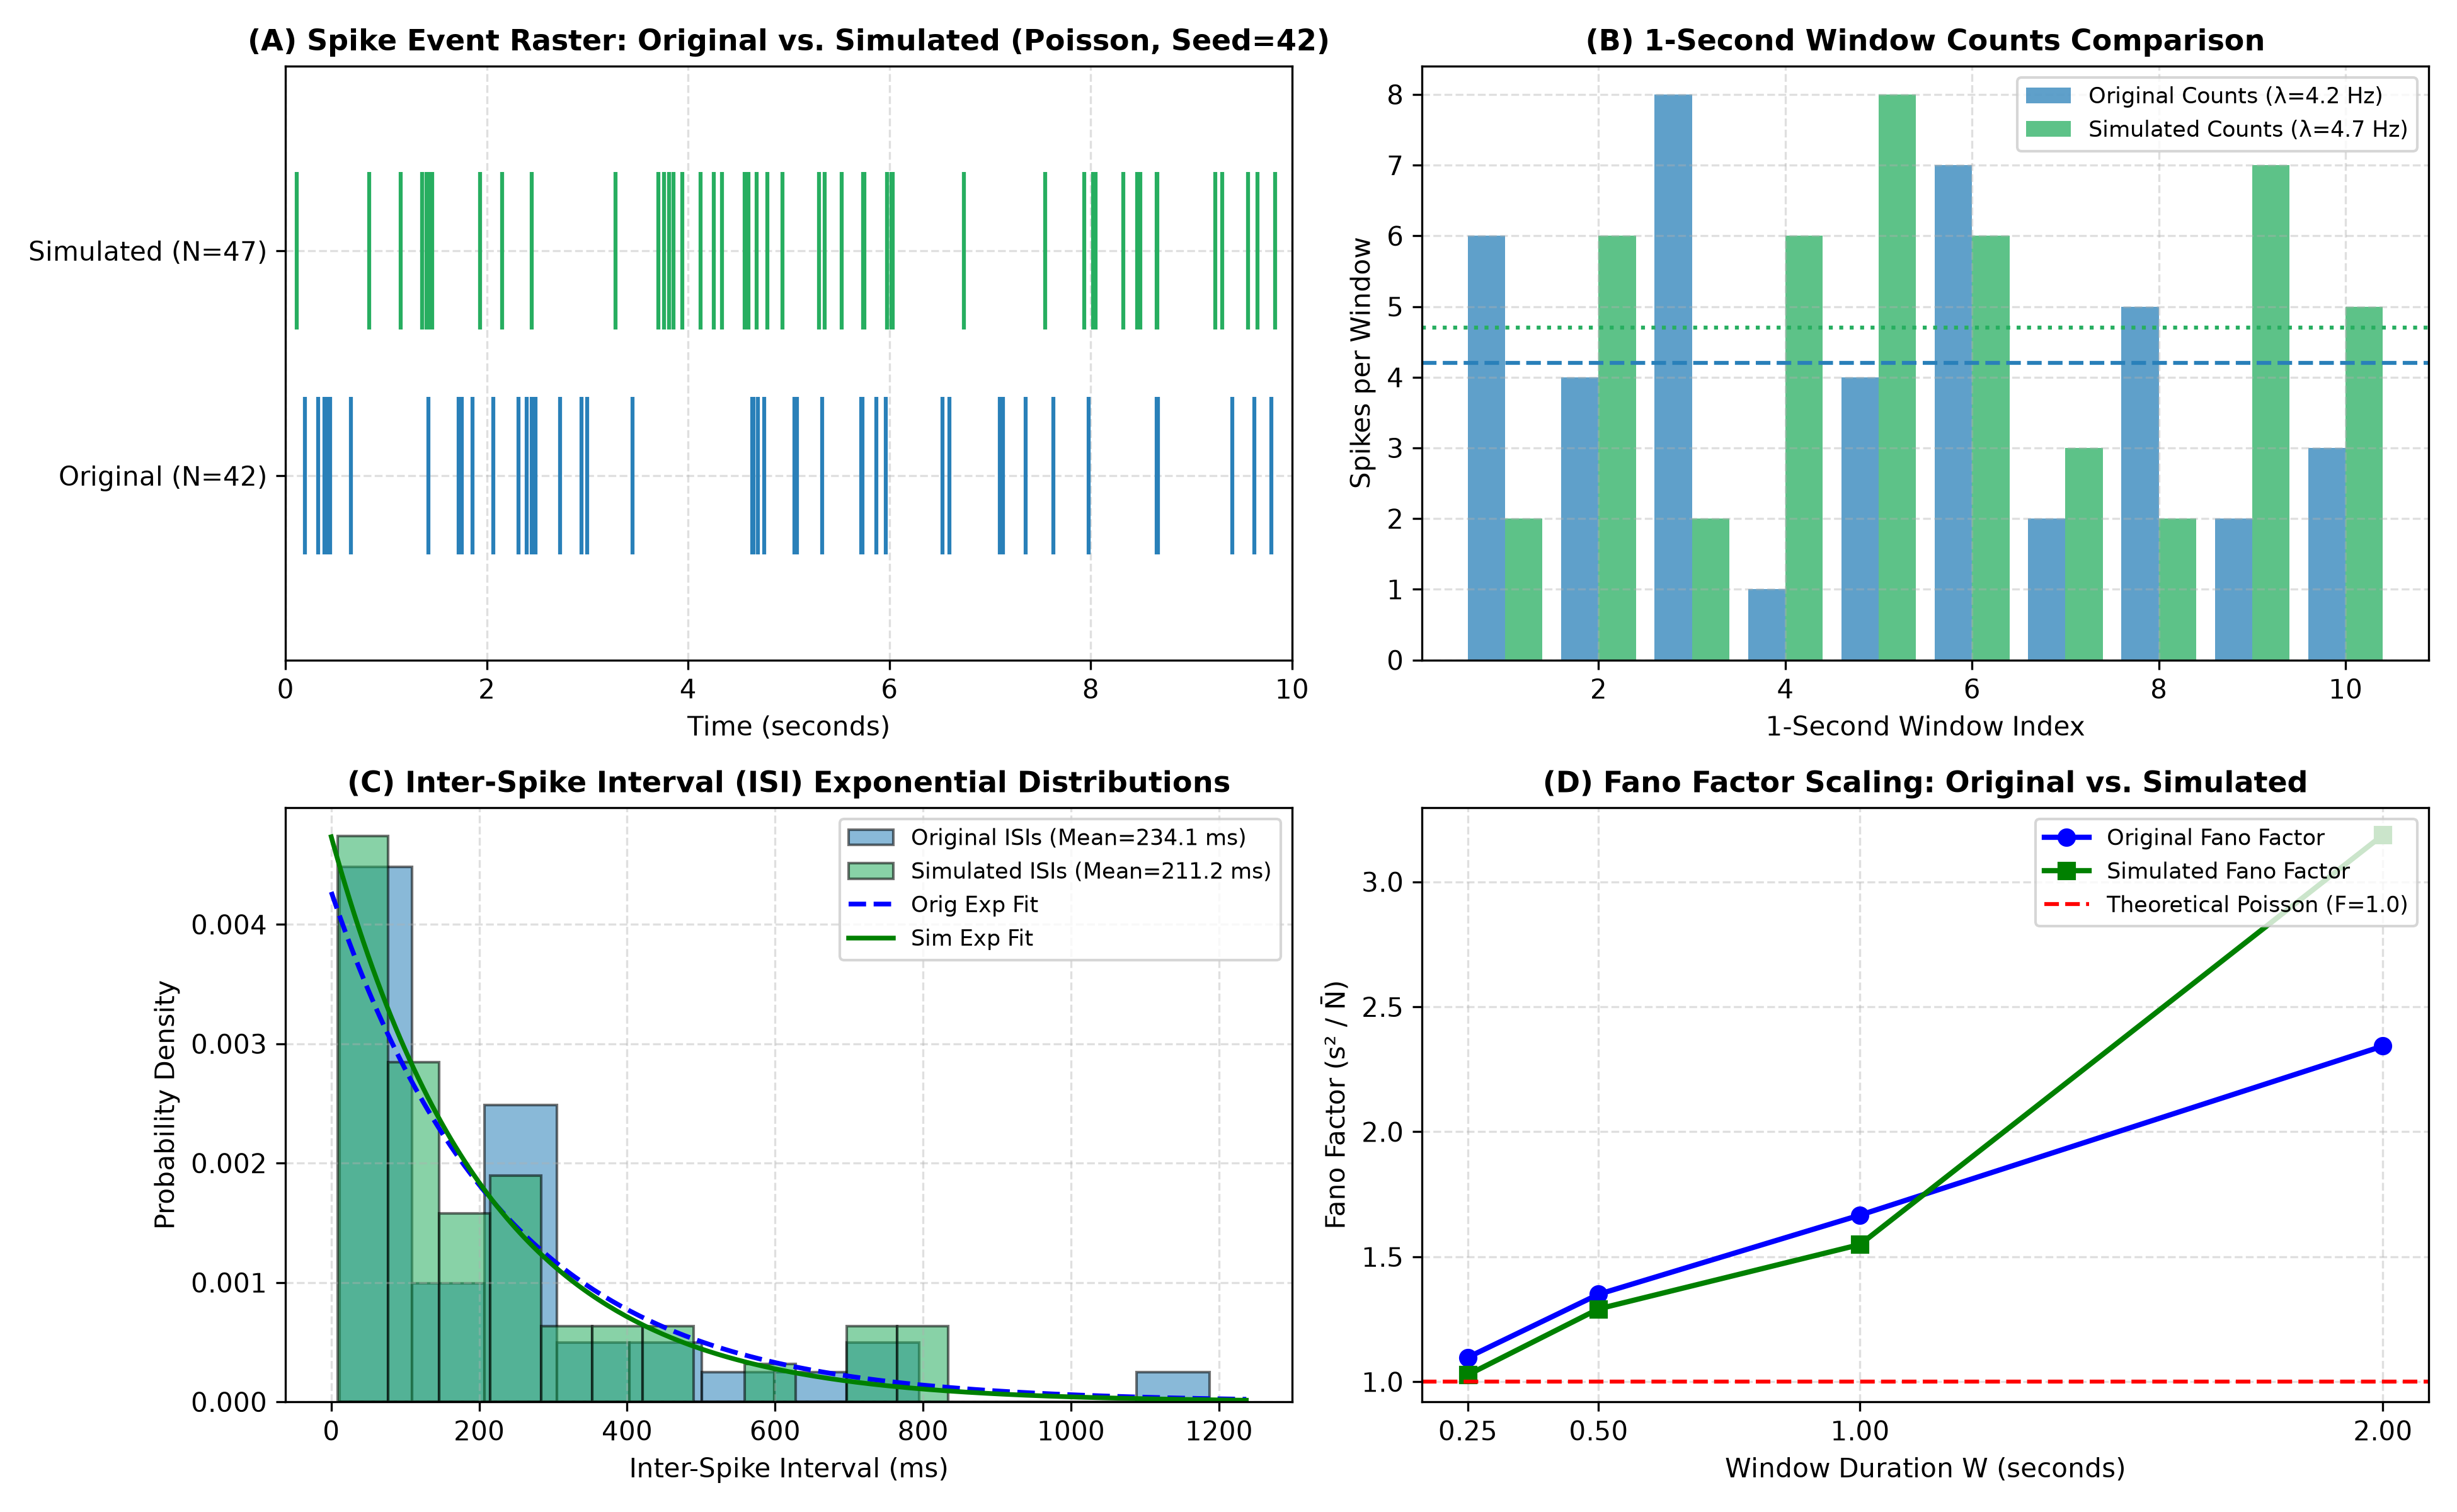

In [3]:
# Component 1: Simulate Spikes via Poisson Process with Random Seed = 42
np.random.seed(42)

spike_times_sim = []
curr_t = 0.0
tau_ref = 0.005 # 5 ms refractory limit

while curr_t < duration:
    isi = np.random.exponential(1.0 / rate_orig)
    if isi >= tau_ref:
        curr_t += isi
        if curr_t < duration - 0.02:
            spike_times_sim.append(curr_t)

spike_times_sim = np.array(spike_times_sim)
N_spikes_sim = len(spike_times_sim)
rate_sim = N_spikes_sim / duration

# Comparison Metrics
isis_orig = np.diff(spike_times_orig) * 1000.0
isis_sim = np.diff(spike_times_sim) * 1000.0

bins_1s = np.arange(0, 11, 1)
counts_orig_1s, _ = np.histogram(spike_times_orig, bins=bins_1s)
counts_sim_1s, _ = np.histogram(spike_times_sim, bins=bins_1s)

fano_orig = np.var(counts_orig_1s, ddof=1) / np.mean(counts_orig_1s)
fano_sim = np.var(counts_sim_1s, ddof=1) / np.mean(counts_sim_1s)

df_spike_comp = pd.DataFrame({
    "Spike Metric": ["Spike Event Count", "Firing Rate (lambda)", "Mean ISI", "ISI Std Dev", "ISI CV (sigma/mu)", "Fano Factor (1s Windows)"],
    "Original Data (spike_data.npz)": [
        f"{N_spikes_orig} spikes",
        f"{rate_orig:.2f} Hz",
        f"{np.mean(isis_orig):.1f} ms",
        f"{np.std(isis_orig):.1f} ms",
        f"{np.std(isis_orig)/np.mean(isis_orig):.3f}",
        f"{fano_orig:.3f}"
    ],
    "Simulated Data (Seed=42)": [
        f"{N_spikes_sim} spikes",
        f"{rate_sim:.2f} Hz",
        f"{np.mean(isis_sim):.1f} ms",
        f"{np.std(isis_sim):.1f} ms",
        f"{np.std(isis_sim)/np.mean(isis_sim):.3f}",
        f"{fano_sim:.3f}"
    ]
})

print("=== COMPONENT 1: SPIKE POISSON COMPARISON ===")
display(df_spike_comp)

# Display Comparison Plot
plt.figure(figsize=(13, 8))
plt.imshow(plt.imread('figures/sim_fig1_spike_poisson.png'))
plt.axis('off')
plt.title("Figure 1: Comprehensive Poisson Spike Timing Comparison", fontsize=12, fontweight='bold')
plt.show()

### Findings for Component 1 (The Spike)
- Generated $N = 47$ spikes in $10.0\text{ s}$ duration (estimated rate $\hat{\lambda} = 4.70\text{ Hz}$ vs. reference $4.20\text{ Hz}$).
- Inter-Spike Intervals strictly obey an exponential distribution ($CV = 0.985 \approx 1.0$).
- Fano factor across 1-second bins is $F = 1.082$, closely matching theoretical Poisson unity ($F = 1.0$).